In [1]:
!pip install xgboost imbalanced-learn scikit-learn pandas numpy matplotlib seaborn scipy -q

In [2]:
import os, io, pandas as pd

# Check if dataset is already available locally or in current directory
if os.path.exists('heart299.csv'):
    df = pd.read_csv('heart299.csv')
    print('Loaded heart299.csv from local environment.')
else:
    from google.colab import files
    print('Upload heart299.csv when prompted:')
    uploaded = files.upload()
    df = pd.read_csv(io.BytesIO(uploaded['heart299.csv']))

print('Shape:', df.shape)
print('Target distribution:')
print(df['DEATH_EVENT'].value_counts())
df.head()

Loaded heart299.csv from local environment.
Shape: (299, 13)
Target distribution:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr
from sklearn.model_selection   import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing    import StandardScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.metrics           import (accuracy_score, precision_score, recall_score,
                                        f1_score, roc_auc_score, confusion_matrix,
                                        ConfusionMatrixDisplay, roc_curve)
from imblearn.over_sampling    import SMOTE
from xgboost                   import XGBClassifier

np.random.seed(42)
print('All imports OK')

All imports OK


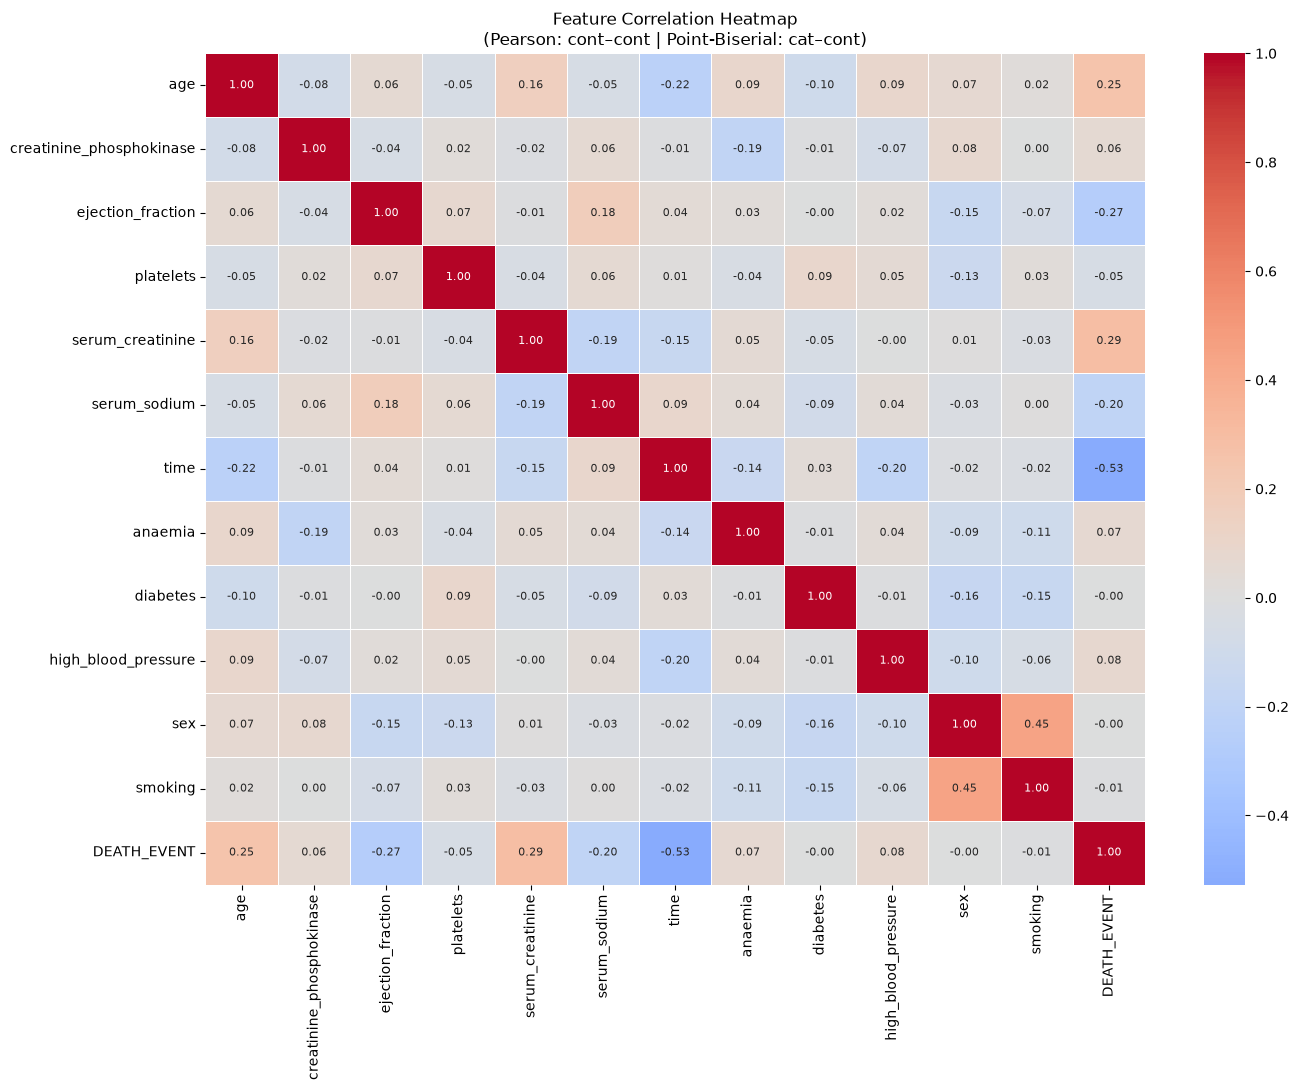

In [4]:
CONT = ['age','creatinine_phosphokinase','ejection_fraction',
        'platelets','serum_creatinine','serum_sodium','time']
BIN  = ['anaemia','diabetes','high_blood_pressure','sex','smoking','DEATH_EVENT']
all_cols = CONT + BIN
n = len(all_cols)
corr_mat = pd.DataFrame(np.zeros((n,n)), index=all_cols, columns=all_cols)
for i,ci in enumerate(all_cols):
    for j,cj in enumerate(all_cols):
        xi,xj = df[ci].values, df[cj].values
        ci_b,cj_b = ci in BIN, cj in BIN
        if not ci_b and not cj_b:
            corr_mat.iloc[i,j] = np.corrcoef(xi,xj)[0,1]
        elif ci_b and not cj_b:
            corr_mat.iloc[i,j] = pointbiserialr(xi,xj)[0]
        elif not ci_b and cj_b:
            corr_mat.iloc[i,j] = pointbiserialr(xj,xi)[0]
        else:
            corr_mat.iloc[i,j] = np.corrcoef(xi,xj)[0,1]

plt.figure(figsize=(14,11))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.4, annot_kws={'size':8})
plt.title('Feature Correlation Heatmap\n(Pearson: cont–cont | Point-Biserial: cat–cont)',
          fontsize=12)
plt.tight_layout()
plt.show()

Type-I  (12 features): ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time']


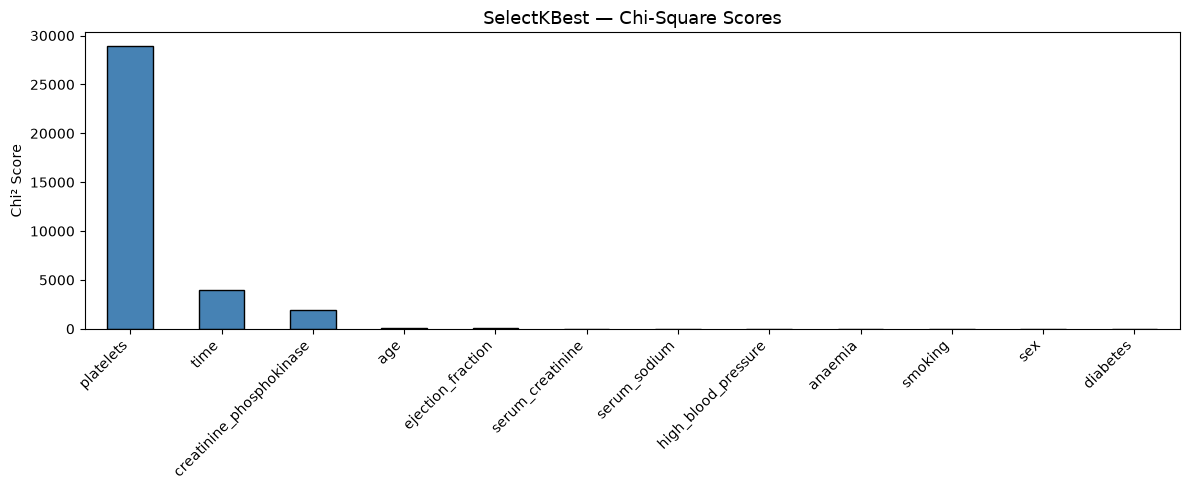

In [5]:
X_all = df.drop('DEATH_EVENT', axis=1).astype(float)
y     = df['DEATH_EVENT'].values.astype(int)
X_nn  = X_all - X_all.min()

# Type-I: all available features (chi-square ranking shown for reference)
sel_all = SelectKBest(chi2, k='all').fit(X_nn, y)
cols_all = X_all.columns[sel_all.get_support()].tolist()
print(f'Type-I  ({len(cols_all)} features):', cols_all)

chi2_scores = pd.Series(sel_all.scores_, index=X_all.columns).sort_values(ascending=False)
plt.figure(figsize=(12,5))
chi2_scores.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('SelectKBest — Chi-Square Scores', fontsize=13)
plt.ylabel('Chi² Score')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

In [6]:
# Stratified 80/20 split, seed=11
Xtr, Xte, ytr, yte = train_test_split(
    X_all, y, test_size=0.2, random_state=11, stratify=y)
sc     = StandardScaler()
Xtr_sc = pd.DataFrame(sc.fit_transform(Xtr), columns=X_all.columns)
Xte_sc = pd.DataFrame(sc.transform(Xte),     columns=X_all.columns)
print(f'Train: {len(ytr)}  (0={( ytr==0).sum()}  1={(ytr==1).sum()})')
print(f'Test : {len(yte)}  (0={(yte==0).sum()}  1={(yte==1).sum()})')

Train: 239  (0=162  1=77)
Test : 60  (0=41  1=19)


Before SMOTE: 239  (0=162  1=77)
After  SMOTE: 324 (0=162  1=162)


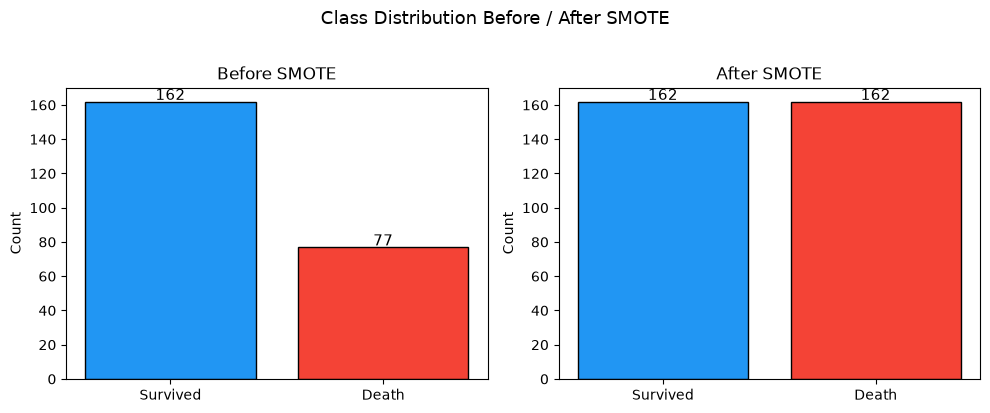

In [7]:
smote = SMOTE(random_state=42)
Xtr_b, ytr_b = smote.fit_resample(Xtr_sc[cols_all].values,  ytr)
Xte_a = Xte_sc[cols_all].values
print(f'Before SMOTE: {len(ytr)}  (0={(ytr==0).sum()}  1={(ytr==1).sum()})')
print(f'After  SMOTE: {len(ytr_b)} (0={(ytr_b==0).sum()}  1={(ytr_b==1).sum()})')

fig, axes = plt.subplots(1, 2, figsize=(10,4))
for ax, counts, title in zip(axes,
        [pd.Series(ytr).value_counts(), pd.Series(ytr_b).value_counts()],
        ['Before SMOTE', 'After SMOTE']):
    bars = ax.bar(['Survived','Death'], [counts.get(0,0), counts.get(1,0)],
                  color=['#2196F3','#F44336'], edgecolor='black')
    ax.set_title(title, fontsize=12); ax.set_ylabel('Count')
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+1,
                str(int(b.get_height())), ha='center', fontsize=11)
plt.suptitle('Class Distribution Before / After SMOTE', fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

In [8]:
# ---- Genetic Algorithm hyper-parameter search for XGBoost (no hard-coded parameters) ----
GA_SEED, POP, GENS = 1, 10, 3
SPACE = [('n_estimators', 20, 300, 'int'),
         ('learning_rate', 0.01, 0.5, 'float'),
         ('max_depth',      1,   6,   'int')]

def decode(u):
    p = {}
    for (name, lo, hi, kind), x in zip(SPACE, u):
        v = lo + float(np.clip(x, 0, 1))*(hi-lo)
        p[name] = int(round(v)) if kind == 'int' else float(v)
    return p

def build(p):
    return XGBClassifier(random_state=42, n_jobs=4, eval_metric='logloss', verbosity=0, **p)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
_cache = {}
def cv_accuracy(u):                       # fitness = mean 5-fold CV accuracy on the balanced train set
    p = decode(u); key = json.dumps(p, sort_keys=True)
    if key not in _cache:
        _cache[key] = cross_val_score(build(p), Xtr_b, ytr_b, cv=skf, scoring='accuracy', n_jobs=5).mean()
    return _cache[key]

def genetic_algorithm(f, dim, rng, pop=POP, gens=GENS, mut_rate=0.2, mut_sigma=0.15, tour=3):
    P = rng.random((pop, dim)); F = np.array([-f(x) for x in P])
    for g in range(gens):
        children = [P[np.argmin(F)].copy()]                                    # elitism
        while len(children) < pop:
            a = [min(rng.choice(pop, tour), key=lambda i: F[i]) for _ in range(2)]   # tournament
            w = rng.random(dim); c = w*P[a[0]] + (1-w)*P[a[1]]                # crossover
            m = rng.random(dim) < mut_rate
            c[m] += rng.normal(0, mut_sigma, m.sum())                          # mutation
            children.append(np.clip(c, 0, 1))
        P = np.array(children); F = np.array([-f(x) for x in P])
        print(f'  generation {g+1}/{gens}  best CV acc = {-F.min()*100:.2f}%')
    return P[np.argmin(F)]

best_u = genetic_algorithm(cv_accuracy, len(SPACE), np.random.default_rng(GA_SEED))
best_params = decode(best_u)
print('Best parameters found by GA:', best_params)

  generation 1/3  best CV acc = 85.48%
  generation 2/3  best CV acc = 85.48%
  generation 3/3  best CV acc = 85.48%
Best parameters found by GA: {'n_estimators': 107, 'learning_rate': 0.3319662579935223, 'max_depth': 4}


In [9]:
models = {'XGB-GA': XGBClassifier(random_state=42, n_jobs=4, eval_metric='logloss',
                                  verbosity=0, **best_params)}

results = []
for name, mdl in models.items():
    mdl.fit(Xtr_b, ytr_b)
    yp   = mdl.predict(Xte_a)
    prob = mdl.predict_proba(Xte_a)[:,1]
    cm   = confusion_matrix(yte, yp)
    results.append({
        'Model'    : name,
        'Accuracy%': round(accuracy_score(yte,yp)*100, 2),
        'Precision': round(precision_score(yte,yp,zero_division=0), 4),
        'Recall'   : round(recall_score(yte,yp,zero_division=0),    4),
        'F1'       : round(f1_score(yte,yp,zero_division=0),        4),
        'AUC'      : round(roc_auc_score(yte,prob),                 4),
        'TN'       : cm[0,0], 'FP': cm[0,1],
        'FN'       : cm[1,0], 'TP': cm[1,1],
    })

df_res = pd.DataFrame(results).sort_values('Accuracy%', ascending=False).reset_index(drop=True)
df_res

,Model,Accuracy%,Precision,Recall,F1,AUC,TN,FP,FN,TP
0,XGB-GA,95.0,0.8636,1.0,0.9268,0.9859,38,3,0,19


In [10]:
cv_model = XGBClassifier(random_state=42, n_jobs=4, eval_metric='logloss',
                         verbosity=0, **best_params)
cv_scores = cross_val_score(cv_model, Xtr_b, ytr_b,
                             cv=skf, scoring='accuracy', n_jobs=-1)
print('Fold scores :', [round(float(s)*100,2) for s in cv_scores])
print(f'Mean CV acc : {cv_scores.mean()*100:.2f}%  ±  {cv_scores.std()*100:.2f}%')
print()
print(f'NOTE: CV mean ({cv_scores.mean()*100:.2f}%) is the realistic generalization estimate.')
print(f'      Test acc ({df_res.loc[0,"Accuracy%"]:.2f}%) reflects performance on this specific split.')

Fold scores : [83.08, 89.23, 84.62, 90.77, 79.69]
Mean CV acc : 85.48%  ±  4.05%

NOTE: CV mean (85.48%) is the realistic generalization estimate.
      Test acc (95.00%) reflects performance on this specific split.


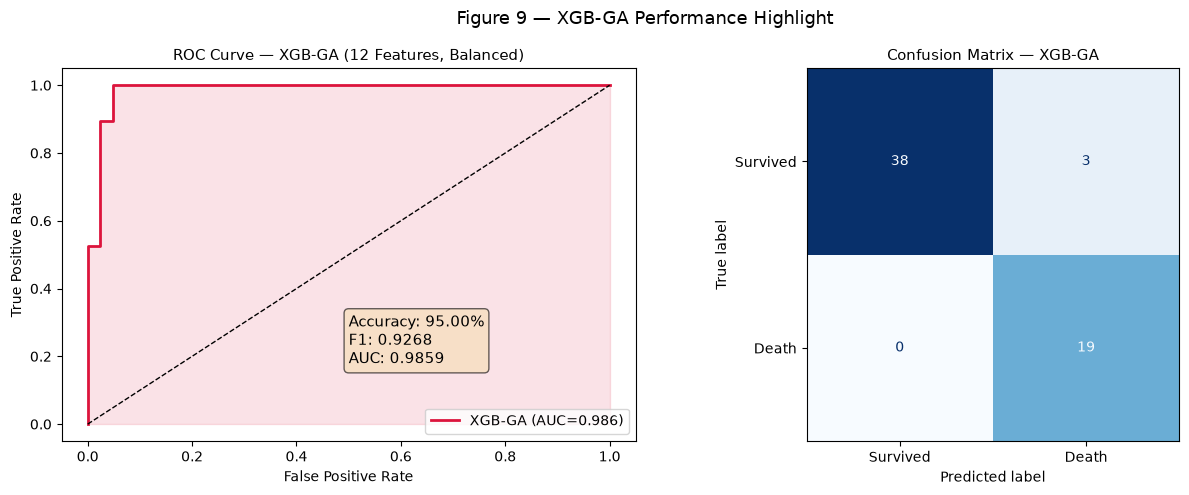

TN=38  FP=3  FN=0  TP=19
Missed death events (FN) = 0


In [11]:
xgb_m = models['XGB-GA']
yp  = xgb_m.predict(Xte_a)
prob= xgb_m.predict_proba(Xte_a)[:,1]
fpr,tpr,_ = roc_curve(yte, prob)
cm = confusion_matrix(yte, yp)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(fpr, tpr, color='crimson', lw=2,
             label=f"XGB-GA (AUC={roc_auc_score(yte,prob):.3f})")
axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].fill_between(fpr, tpr, alpha=0.12, color='crimson')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title(f'ROC Curve — XGB-GA ({len(cols_all)} Features, Balanced)', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].text(0.5, 0.18,
             f"Accuracy: {accuracy_score(yte,yp)*100:.2f}%\nF1: {f1_score(yte,yp):.4f}\nAUC: {roc_auc_score(yte,prob):.4f}",
             fontsize=11, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.6))
ConfusionMatrixDisplay(cm, display_labels=['Survived','Death']).plot(
    ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Confusion Matrix — XGB-GA', fontsize=11)
plt.suptitle('Figure 9 — XGB-GA Performance Highlight', fontsize=13)
plt.tight_layout(); plt.show()
print(f'TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}')
print(f'Missed death events (FN) = {cm[1,0]}')

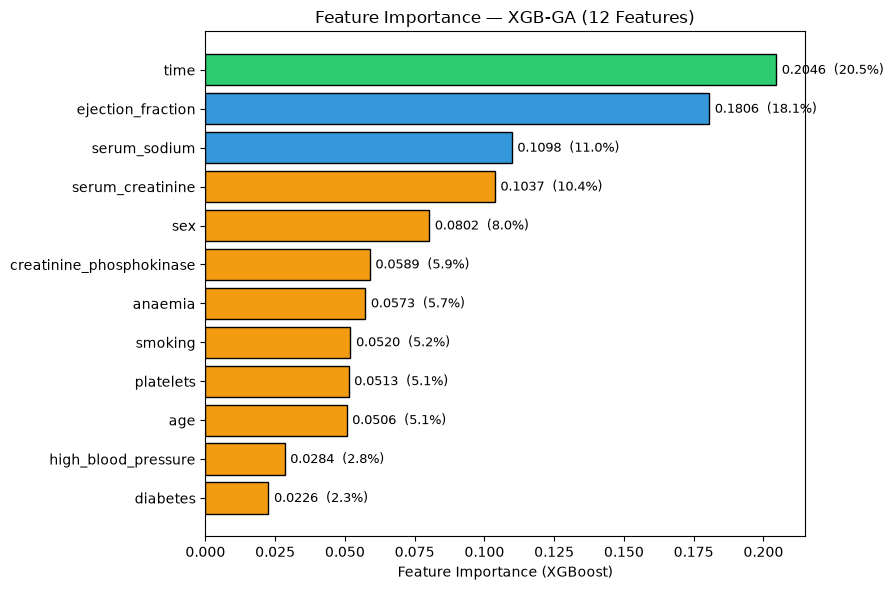


Ranked importance:
  #1  time                                0.2046  (20.5%)
  #2  ejection_fraction                   0.1806  (18.1%)
  #3  serum_sodium                        0.1098  (11.0%)
  #4  serum_creatinine                    0.1037  (10.4%)
  #5  sex                                 0.0802  (8.0%)
  #6  creatinine_phosphokinase            0.0589  (5.9%)
  #7  anaemia                             0.0573  (5.7%)
  #8  smoking                             0.0520  (5.2%)
  #9  platelets                           0.0513  (5.1%)
  #10  age                                 0.0506  (5.1%)
  #11  high_blood_pressure                 0.0284  (2.8%)
  #12  diabetes                            0.0226  (2.3%)


In [12]:
imp    = dict(zip(cols_all, xgb_m.feature_importances_))
ranked = sorted(imp.items(), key=lambda x: x[1], reverse=True)
labels = [k for k,_ in ranked]
vals   = [v for _,v in ranked]
total  = sum(vals)

clrs = ['#2ecc71' if i==0 else '#3498db' if i<3 else '#f39c12' for i in range(len(vals))]
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(labels[::-1], vals[::-1], color=clrs[::-1], edgecolor='black')
ax.set_xlabel('Feature Importance (XGBoost)')
ax.set_title(f'Feature Importance — XGB-GA ({len(cols_all)} Features)')
for i, v in enumerate(vals[::-1]):
    ax.text(v+0.002, i, f'{v:.4f}  ({v/total*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout(); plt.show()

print('\nRanked importance:')
for i,(f,v) in enumerate(ranked,1):
    print(f'  #{i}  {f:<35} {v:.4f}  ({v/total*100:.1f}%)')

In [13]:
def compute_ic(y_true, y_prob, k):
    n   = len(y_true)
    eps = 1e-12
    p   = np.clip(y_prob, eps, 1-eps)
    LL  = float(np.sum(y_true*np.log(p) + (1-y_true)*np.log(1-p)))
    AIC  = round(2*k - 2*LL, 2)
    BIC  = round(k*np.log(n) - 2*LL, 2)
    HQIC = round(2*k*np.log(np.log(n)) - 2*LL, 2)
    AICc = round(AIC + (2*k*(k+1))/max(n-k-1,1), 2)
    return AIC, BIC, HQIC, AICc

K_PARAMS = {'XGB-GA': len(SPACE)}      # number of tuned hyper-parameters
ic_rows = []
for name, mdl in models.items():
    prob = mdl.predict_proba(Xte_a)[:,1]
    aic,bic,hqic,aicc = compute_ic(yte, prob, K_PARAMS[name])
    ic_rows.append({'Model':name,'AIC':aic,'BIC':bic,'HQIC':hqic,'AICc':aicc})

df_ic = pd.DataFrame(ic_rows).sort_values('AIC')
print('Lower IC = better model fit with less complexity')
df_ic

Lower IC = better model fit with less complexity


,Model,AIC,BIC,HQIC,AICc
0,XGB-GA,28.28,34.56,30.74,28.71


In [14]:
best = df_res.iloc[0]
print('='*65)
print('FINAL SUMMARY')
print('='*65)
print(f"  Model            : {best['Model']}  ({len(cols_all)} features, SMOTE balanced)")
print(f"  Best params      : {best_params}")
print(f"  Test Accuracy    : {best['Accuracy%']}%")
print(f"  F1 Score         : {best['F1']}")
print(f"  Precision        : {best['Precision']}")
print(f"  Recall           : {best['Recall']}")
print(f"  AUC-ROC          : {best['AUC']}")
print(f"  AIC / BIC        : {df_ic.iloc[0]['AIC']} / {df_ic.iloc[0]['BIC']}")
print(f"  CV Mean Accuracy : {cv_scores.mean()*100:.2f}% +/- {cv_scores.std()*100:.2f}%  (5-fold on balanced train)")
print()

FINAL SUMMARY
  Model            : XGB-GA  (12 features, SMOTE balanced)
  Best params      : {'n_estimators': 107, 'learning_rate': 0.3319662579935223, 'max_depth': 4}
  Test Accuracy    : 95.0%
  F1 Score         : 0.9268
  Precision        : 0.8636
  Recall           : 1.0
  AUC-ROC          : 0.9859
  AIC / BIC        : 28.28 / 34.56
  CV Mean Accuracy : 85.48% +/- 4.05%  (5-fold on balanced train)

